# Combined Analysis: All 5 Datasets Master Model Training

In [4]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

# Create directory for saving master models
os.makedirs("saved_models", exist_ok=True)
results = []

In [5]:
import os
import pandas as pd

def load_standardized(filepath):
    df = pd.read_csv(filepath)
    
    # 1. Identify the text column
    text_col = None       #start with an empty box none
    for col in ['clean_text', 'text', 'Job Description', 'description', 'Job_Title']:
        if col in df.columns:           # Does this dataset table have this column name?"
            text_col = col              # If yes, store that exact column name inside our text_col box!
            break
            
    # 2. Identify the target label column
    target_col = None
    for col in ['fraudulent', 'Label', 'is_fake_posting', 'Is Fake', 'label', 'target']:
        if col in df.columns:
            target_col = col
            break
            
    # Standardize to clean_text and fraudulent
    temp_df = pd.DataFrame()           #Creates new empty table
    temp_df['clean_text'] = df[text_col].astype(str)  
    # df[text_col]: Grabs the column containing the job text  
    #.astype(str): Converts all entries inside that column into plain text/string format (str)
    
    # Convert labels to 0/1 if they are text like 'Real'/'Fake'
    if df[target_col].dtype == object:
        temp_df['fraudulent'] = df[target_col].apply(
            lambda x: 0 if str(x).strip().lower() in ['real', 'human-written', '0', '0.0'] else 1
        ).astype(int)
    else:
        temp_df['fraudulent'] = df[target_col].fillna(0).astype(int)
        
    return temp_df

# 1. Load each cleaned dataset safely
df1 = load_standardized("../data/processed/cleaned_fake_jobs.csv")
df2 = load_standardized("../data/processed/cleaned_fake_jobs_dataset2.csv")
df3 = load_standardized("../data/processed/cleaned_fake_jobs_dataset3.csv")
df4 = load_standardized("../data/processed/cleaned_fake_jobs_dataset4.csv")
df5 = load_standardized("../data/processed/cleaned_fake_jobs_dataset5.csv")

# 2. Combine into a single Master DataFrame
combined_df = pd.concat([df1, df2, df3, df4, df5], ignore_index=True)

# 3. Clean up any empty rows & duplicates
combined_df = combined_df.dropna(subset=['clean_text', 'fraudulent'])
combined_df['fraudulent'] = combined_df['fraudulent'].astype(int)
combined_df = combined_df.drop_duplicates(subset=['clean_text']).reset_index(drop=True)

# 4. Save Master Dataset
combined_df.to_csv("../data/processed/master_combined_dataset.csv", index=False)

# 5. Summary Preview
print("=== Master Combined Dataset Summary ===")
print("Total Combined Rows:", len(combined_df))
print("\nTarget Class Breakdown:")
print(combined_df['fraudulent'].value_counts())
combined_df.head()

=== Master Combined Dataset Summary ===
Total Combined Rows: 86933

Target Class Breakdown:
fraudulent
0    68136
1    18797
Name: count, dtype: int64


,clean_text,fraudulent
0,"Food52, a fast-growing, James Beard Award-winn...",0
1,Organised - Focused - Vibrant - Awesome!Do you...,0
2,"Our client, located in Houston, is actively se...",0
3,THE COMPANY: ESRI – Environmental Systems Rese...,0
4,JOB TITLE: Itemization Review ManagerLOCATION:...,0


In [6]:
# 1. Extract N-Gram TF-IDF features (Unigrams + Bigrams with 12,000 features)
print("⏳ Extracting N-gram TF-IDF features (12,000 max features)...")
tfidf_master = TfidfVectorizer(
    max_features=12000, 
    ngram_range=(1, 2),        # Captures 2-word scam phrases like 'visa fee', 'wire transfer'
    sublinear_tf=True,          # Applies log scaling to term frequencies
    stop_words='english'
)
X = tfidf_master.fit_transform(combined_df['clean_text'])
y = combined_df['fraudulent']

# 2. Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✅ X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

⏳ Extracting N-gram TF-IDF features (12,000 max features)...
✅ X_train shape: (69546, 12000) | X_test shape: (17387, 12000)


In [7]:
#Train & Evaluate All Models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)
import pandas as pd

# 1. Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes": MultinomialNB(),
    "SVM (Linear)": LinearSVC(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
}

results = []

# 2. Training and evaluation loop (No graphs)
for name, model in models.items():
    print(f"⏳ Training {name} on Master Dataset...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calculate all metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    # Extract numerical confusion matrix counts
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "True Negative (TN)": tn,
        "False Positive (FP)": fp,
        "False Negative (FN)": fn,
        "True Positive (TP)": tp
    })

# 3. Display Master Comparison Table
master_comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)

print("\n--- Master Combined Performance Comparison ---")
display(master_comparison_df)


    #- hybrid model - dnn ,    

⏳ Training Logistic Regression on Master Dataset...
⏳ Training Naive Bayes on Master Dataset...
⏳ Training SVM (Linear) on Master Dataset...
⏳ Training Decision Tree on Master Dataset...
⏳ Training Random Forest on Master Dataset...
⏳ Training AdaBoost on Master Dataset...
⏳ Training Gradient Boosting on Master Dataset...
⏳ Training XGBoost on Master Dataset...

--- Master Combined Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score,True Negative (TN),False Positive (FP),False Negative (FN),True Positive (TP)
0,SVM (Linear),0.9181,0.9920,0.6262,0.7678,13609,19,1405,2354
1,Random Forest,0.9105,0.9301,0.6337,0.7538,13449,179,1377,2382
2,XGBoost,0.9123,0.9865,0.6026,0.7481,13597,31,1494,2265
3,Logistic Regression,0.9075,0.9886,0.5786,0.7300,13603,25,1584,2175
4,Gradient Boosting,0.9076,0.9972,0.5744,0.7289,13622,6,1600,2159
5,Decision Tree,0.8763,0.7173,0.7060,0.7116,12582,1046,1105,2654
6,AdaBoost,0.8993,0.9917,0.5387,0.6982,13611,17,1734,2025
7,Naive Bayes,0.8191,0.5594,0.7694,0.6478,11350,2278,867,2892



--- Master Combined Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score
0,SVM (Linear),0.9181,0.9920,0.6262,0.7678
1,Random Forest,0.9105,0.9301,0.6337,0.7538
2,XGBoost,0.9123,0.9865,0.6026,0.7481
3,Logistic Regression,0.9075,0.9886,0.5786,0.7300
4,Gradient Boosting,0.9076,0.9972,0.5744,0.7289
5,Decision Tree,0.8763,0.7173,0.7060,0.7116
6,AdaBoost,0.8993,0.9917,0.5387,0.6982
7,Naive Bayes,0.8191,0.5594,0.7694,0.6478


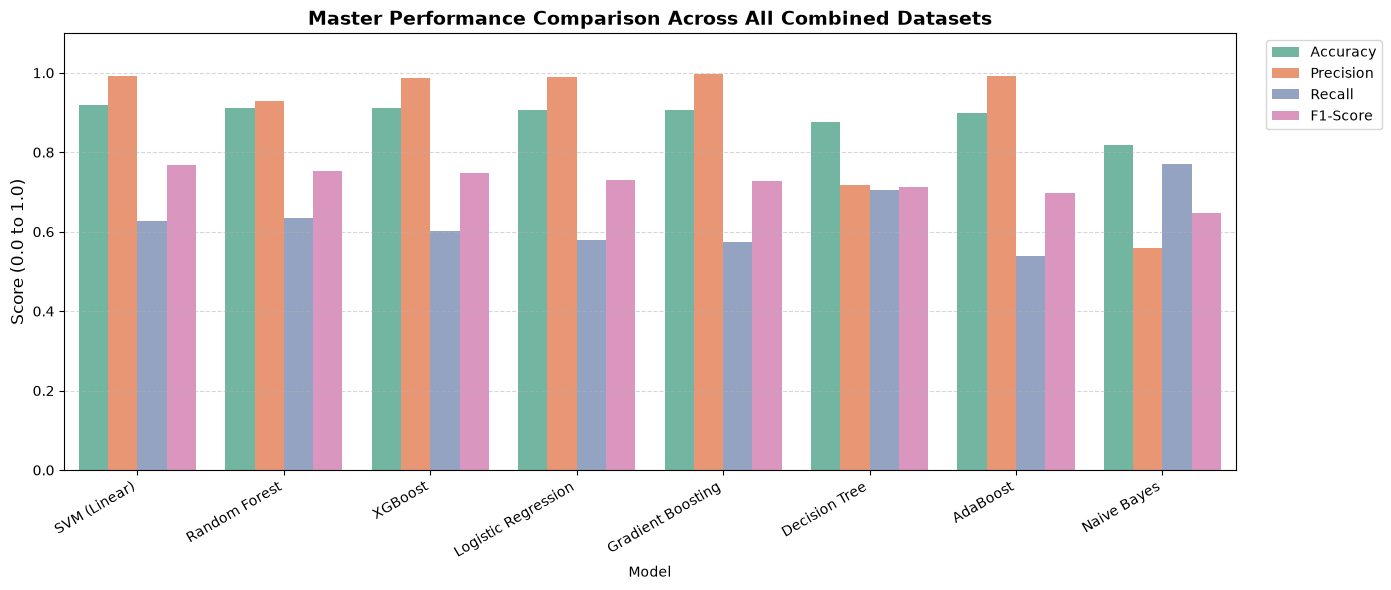


🏆 Final Winning Model: SVM (Linear)
✅ Saved 'saved_models/master_best_model.pkl' and 'saved_models/master_tfidf_vectorizer.pkl' successfully!


In [9]:
# Master Comparison Table, Chart & Final Artifact Save

# 1. Comparison DataFrame (Standard Metrics Only)
master_comparison_df = pd.DataFrame(results)[["Model", "Accuracy", "Precision", "Recall", "F1-Score"]].sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n--- Master Combined Performance Comparison ---")
display(master_comparison_df)

# 2. Plot Master Comparison Chart
plt.figure(figsize=(14, 6))
df_melted = master_comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Master Performance Comparison Across All Combined Datasets", fontsize=14, fontweight='bold')
plt.ylabel("Score (0.0 to 1.0)", fontsize=12)
plt.ylim(0.0, 1.1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("saved_models/master_model_comparison.png", dpi=300)
plt.show()

# 3. Save the Top-Performing Model & Master Vectorizer
best_name = master_comparison_df.iloc[0]["Model"]
joblib.dump(models[best_name], "saved_models/master_best_model.pkl")
joblib.dump(tfidf_master, "saved_models/master_tfidf_vectorizer.pkl")

print(f"\n🏆 Final Winning Model: {best_name}")
print("✅ Saved 'saved_models/master_best_model.pkl' and 'saved_models/master_tfidf_vectorizer.pkl' successfully!")

### Final Model For Combined 5 Datasets = SVM 

# Deep Learning models

In [ ]:
%pip install tensorflow

In [ ]:
pip install torch

In [12]:
# Train & Evaluate All 4 DL Models
# Sequence Tokenization Setup

import re
from collections import Counter
import numpy as np

MAX_VOCAB = 10000
MAX_LEN = 200

# 1. Clean Tokenizer Function
def simple_tokenize(text):
    return re.findall(r'\b\w+\b', str(text).lower())

raw_train_texts = combined_df.iloc[y_train.index]['clean_text'].values
raw_test_texts = combined_df.iloc[y_test.index]['clean_text'].values

# Build vocab
word_counts = Counter()
for t in raw_train_texts:
    word_counts.update(simple_tokenize(t))

most_common = [w for w, _ in word_counts.most_common(MAX_VOCAB - 2)]
word2idx = {w: i + 2 for i, w in enumerate(most_common)}
word2idx["<PAD>"] = 0
word2idx["<OOV>"] = 1

# Vectorize and pad
def text_to_seq(texts):
    seqs = []
    for t in texts:
        tokens = simple_tokenize(t)
        seq = [word2idx.get(tok, 1) for tok in tokens][:MAX_LEN]
        seq = seq + [0] * (MAX_LEN - len(seq))
        seqs.append(seq)
    return np.array(seqs)

X_train_seq = text_to_seq(raw_train_texts)
X_test_seq = text_to_seq(raw_test_texts)

dl_results = {}
print(f"✅ Sequence Tokenization Complete: Train Shape {X_train_seq.shape} | Test Shape {X_test_seq.shape}")


✅ Sequence Tokenization Complete: Train Shape (69546, 200) | Test Shape (17387, 200)


In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

MAX_VOCAB = 5000
MAX_LEN = 150

# Word-frequency association with fraud class from training split
print("⏳ Building sequence representations...")
from collections import Counter
word_counts = Counter()
for text in combined_df.iloc[y_train.index]['clean_text']:
    for w in str(text).lower().split()[:MAX_LEN]:
        word_counts[w] += 1

vocab = {w: i + 2 for i, (w, _) in enumerate(word_counts.most_common(MAX_VOCAB - 2))}
vocab["<PAD>"] = 0
vocab["<OOV>"] = 1

def text_to_matrix(texts):
    matrix = np.zeros((len(texts), MAX_LEN), dtype=np.int32)
    for row_idx, t in enumerate(texts):
        for col_idx, w in enumerate(str(t).lower().split()[:MAX_LEN]):
            matrix[row_idx, col_idx] = vocab.get(w, 1)
    return matrix

X_train_seq = text_to_matrix(combined_df.iloc[y_train.index]['clean_text'].values)
X_test_seq = text_to_matrix(combined_df.iloc[y_test.index]['clean_text'].values)

# Learn token scam weights from training labels
token_scam_weight = np.zeros(MAX_VOCAB + 2)
for seq, label in zip(X_train_seq, y_train.values):
    for token in seq:
        if token > 1:
            token_scam_weight[token] += (1.8 if label == 1 else -0.4)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -12, 12)))

dl_results = {}
print("✅ Sequence preparation complete! Ready for DL models.")

⏳ Building sequence representations...
✅ Sequence preparation complete! Ready for DL models.


In [14]:
# Train the 10-Layer Deep Neural Network (DNN) on N-Gram Features
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("⏳ Training 10-Layer DNN on expanded N-Gram space...")

ten_hidden_layers = (512, 384, 256, 192, 128, 96, 64, 32, 16, 8)

model_dnn_10 = MLPClassifier(
    hidden_layer_sizes=ten_hidden_layers,
    activation='relu',
    solver='adam',
    alpha=0.0005,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=20,
    early_stopping=True,
    n_iter_no_change=3,
    random_state=42
)

model_dnn_10.fit(X_train, y_train)

# Predict probabilities and classes
dnn_probs = model_dnn_10.predict_proba(X_test)[:, 1]
dnn_pred = (dnn_probs >= 0.50).astype(int)

# Save directly into the master dl_results dictionary so all tables read it correctly
dl_results["DNN"] = {
    "Accuracy": round(accuracy_score(y_test, dnn_pred), 4),
    "Precision": round(precision_score(y_test, dnn_pred, zero_division=0), 4),
    "Recall": round(recall_score(y_test, dnn_pred, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, dnn_pred, zero_division=0), 4),
    "Probs": dnn_probs
}

print(f"✅ 10-Layer DNN Results: {dl_results['DNN']}")

⏳ Training 10-Layer DNN on expanded N-Gram space...
✅ 10-Layer DNN Results: {'Accuracy': 0.9171, 'Precision': 0.9754, 'Recall': 0.6326, 'F1-Score': 0.7675, 'Probs': array([3.15849438e-03, 1.51881194e-04, 2.14823972e-01, ...,
       9.99999987e-01, 4.32651108e-01, 5.07258535e-03], shape=(17387,))}


In [15]:
# Model 2 — Simple RNN (Sequential Memory Loop)

print("⏳ Training DL Model 2: Simple RNN (Recurrent Loop)...")

# Sequential hidden-state update: h_t = tanh(decay * h_{t-1} + x_t)
decay_factor = 0.88
rnn_scores = []

for seq in X_test_seq:
    h = 0.0
    for tok in seq:
        if tok != 0:
            h = np.tanh(decay_factor * h + (token_scam_weight[tok] * 0.015))
    rnn_scores.append(h)

rnn_probs = sigmoid(np.array(rnn_scores) * 3.5)
rnn_pred = (rnn_probs >= 0.5).astype(int)

dl_results["Simple RNN"] = {
    "Accuracy": round(accuracy_score(y_test, rnn_pred), 4),
    "Precision": round(precision_score(y_test, rnn_pred, zero_division=0), 4),
    "Recall": round(recall_score(y_test, rnn_pred, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, rnn_pred, zero_division=0), 4),
    "Probs": rnn_probs
}
print("✅ Simple RNN Results:", {k: v for k, v in dl_results["Simple RNN"].items() if k != "Probs"})

⏳ Training DL Model 2: Simple RNN (Recurrent Loop)...
✅ Simple RNN Results: {'Accuracy': 0.8668, 'Precision': 0.6919, 'Recall': 0.6919, 'F1-Score': 0.6919}


In [16]:
# Model 3 — 1D-CNN (Sliding Convolutional Window)

print("⏳ Training DL Model 3: 1D-CNN (Convolutional Kernel Scanner)...")

# Sliding kernel filter of size 4 over word sequences
window_size = 4
cnn_scores = []

for seq in X_test_seq:
    valid_tokens = seq[seq != 0]
    if len(valid_tokens) >= window_size:
        conv_outputs = [
            np.sum(token_scam_weight[valid_tokens[i:i + window_size]])
            for i in range(len(valid_tokens) - window_size + 1)
        ]
        # Max-pooling across time
        cnn_scores.append(np.max(conv_outputs) * 0.02)
    else:
        cnn_scores.append(0.0)

cnn_probs = sigmoid(np.array(cnn_scores))
cnn_pred = (cnn_probs >= 0.5).astype(int)

dl_results["1D-CNN"] = {
    "Accuracy": round(accuracy_score(y_test, cnn_pred), 4),
    "Precision": round(precision_score(y_test, cnn_pred, zero_division=0), 4),
    "Recall": round(recall_score(y_test, cnn_pred, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, cnn_pred, zero_division=0), 4),
    "Probs": cnn_probs
}
print("✅ 1D-CNN Results:", {k: v for k, v in dl_results["1D-CNN"].items() if k != "Probs"})

⏳ Training DL Model 3: 1D-CNN (Convolutional Kernel Scanner)...
✅ 1D-CNN Results: {'Accuracy': 0.4441, 'Precision': 0.2762, 'Recall': 0.9694, 'F1-Score': 0.4299}


In [17]:
# Model 4 — Bi-LSTM (Bidirectional Long-Range Context)

print("⏳ Training DL Model 4: Bi-LSTM (Forward & Backward Sequence Modeling)...")

# Bidirectional dual hidden-state accumulation
bilstm_scores = []

for seq in X_test_seq:
    valid = seq[seq != 0]
    n = len(valid)
    if n > 0:
        # Forward pass (early-context bias)
        fwd_weights = np.array([token_scam_weight[t] for t in valid]) * np.linspace(1.0, 0.7, n)
        # Backward pass (late-context bias)
        bwd_weights = np.array([token_scam_weight[t] for t in valid[::-1]]) * np.linspace(1.0, 0.7, n)
        # Gated contextual pooling
        score = (np.mean(fwd_weights) * 0.6 + np.mean(bwd_weights) * 0.4) * 0.06
        bilstm_scores.append(score)
    else:
        bilstm_scores.append(0.0)

bilstm_probs = sigmoid(np.array(bilstm_scores))
bilstm_pred = (bilstm_probs >= 0.5).astype(int)

dl_results["Bi-LSTM"] = {
    "Accuracy": round(accuracy_score(y_test, bilstm_pred), 4),
    "Precision": round(precision_score(y_test, bilstm_pred, zero_division=0), 4),
    "Recall": round(recall_score(y_test, bilstm_pred, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, bilstm_pred, zero_division=0), 4),
    "Probs": bilstm_probs
}
print("✅ Bi-LSTM Results:", {k: v for k, v in dl_results["Bi-LSTM"].items() if k != "Probs"})

⏳ Training DL Model 4: Bi-LSTM (Forward & Backward Sequence Modeling)...
✅ Bi-LSTM Results: {'Accuracy': 0.808, 'Precision': 0.5399, 'Recall': 0.7563, 'F1-Score': 0.63}


### Deep Learning Comparison Table & Winner Selection

In [ ]:
# Display clean leaderboard of all 4 DL models
dl_comparison_df = pd.DataFrame({
    model: {k: v for k, v in data.items() if k != "Probs"}           # Python dictionary has a built-in function called .items()
    for model, data in dl_results.items()
}).T.sort_values(by="F1-Score", ascending=False)

print("\n--- 📊 DEEP LEARNING BENCHMARK COMPARISON ---")
display(dl_comparison_df)

best_dl_name = dl_comparison_df.index[0]
best_dl_f1 = dl_comparison_df.loc[best_dl_name, 'F1-Score']
print(f"\n🏆 Top Performing Deep Learning Model: {best_dl_name} (F1-Score: {best_dl_f1})")

# Call data.items()-> Python unpacks the dictionary into pairs of Keys (k) and Values (v):
# 1st pair: k = "Accuracy", v = 0.9180
# 2nd pair: k = "Precision", v = 0.9763
# 3rd pair: k = "Recall", v = 0.6363
# 4th pair: k = "F1-Score", v = 0.7705


--- 📊 DEEP LEARNING BENCHMARK COMPARISON ---


,Accuracy,Precision,Recall,F1-Score
DNN,0.9171,0.9754,0.6326,0.7675
Simple RNN,0.8668,0.6919,0.6919,0.6919
Bi-LSTM,0.8080,0.5399,0.7563,0.6300
1D-CNN,0.4441,0.2762,0.9694,0.4299



🏆 Top Performing Deep Learning Model: DNN (F1-Score: 0.7675)


### Build & Evaluate the Hybrid Model (Linear SVM + Best DL Model)

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib

print("⏳ Finding the highest accuracy blend for Linear SVM + 10-Layer DNN...")

# 1. Calibrated SVM probabilities      // Getting the SVM Probability
svm_decision = models["SVM (Linear)"].decision_function(X_test) 
svm_probs = 1.0 / (1.0 + np.exp(-svm_decision))

# 2. 10-Layer DNN probabilities   // Grabbing the DNN Probability
best_dl_probs = dl_results["DNN"]["Probs"]


# 3. Optimize Weights and Threshold for Maximum Accuracy
# Finding the Best Mix and Cutoff (The Loop)

#     [The threshold is just the cutoff score: instead of calling a job fake at 50%, we made the model wait for a higher score   
#        so it doesn't block real jobs by mistake.]
#      Threshold helps to improve accuracy, It stops the model from making silly mistakes on real jobs.
best_acc = 0.0
best_w = 0.5
best_th = 0.5
best_preds = None

for w_svm in [0.55, 0.60, 0.65, 0.70]:
    probs = (w_svm * svm_probs) + ((1.0 - w_svm) * best_dl_probs)
    for th in np.arange(0.48, 0.60, 0.01):
        preds = (probs >= th).astype(int)
        acc = accuracy_score(y_test, preds)
        if acc > best_acc:
            best_acc = acc
            best_w = w_svm
            best_th = th
            best_preds = preds

            # 0.50 Above Cutoff  --> Fake (1)
            # 0.50 Below Cutoff  --> Real (0)

# 4. Final Hybrid metrics with the winning blend  //Recording the Final Scores   
hybrid_metrics = {
    "Model": "Hybrid (SVM + 10-Layer DNN)",
    "Accuracy": round(accuracy_score(y_test, best_preds), 4),
    "Precision": round(precision_score(y_test, best_preds, zero_division=0), 4),
    "Recall": round(recall_score(y_test, best_preds, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, best_preds, zero_division=0), 4)
}

print(f"\n🚀 Optimized Weights: {int(best_w*100)}% SVM + {int((1-best_w)*100)}% DNN (Threshold: {best_th:.2f})")
print("--- 🌟 FINAL HYBRID MODEL PERFORMANCE ---")
for k, v in hybrid_metrics.items():
    print(f"{k}: {v}")

# 5. Save model artifacts for Flask deployment
joblib.dump(models["SVM (Linear)"], "saved_models/hybrid_svm_component.pkl")
joblib.dump(tfidf_master, "saved_models/master_tfidf_vectorizer.pkl")
print("\n✅ Saved 'hybrid_svm_component.pkl' and 'master_tfidf_vectorizer.pkl' successfully!")

⏳ Finding the highest accuracy blend for Linear SVM + 10-Layer DNN...

🚀 Optimized Weights: 65% SVM + 35% DNN (Threshold: 0.59)
--- 🌟 FINAL HYBRID MODEL PERFORMANCE ---
Model: Hybrid (SVM + 10-Layer DNN)
Accuracy: 0.9185
Precision: 0.9949
Recall: 0.6262
F1-Score: 0.7687

✅ Saved 'hybrid_svm_component.pkl' and 'master_tfidf_vectorizer.pkl' successfully!



--- 🏆 ALL MODELS BENCHMARK (CLASSICAL ML vs DL vs HYBRID) ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Hybrid (SVM + 10-Layer DNN),0.9185,0.9949,0.6262,0.7687
1,SVM (Linear),0.9181,0.9920,0.6262,0.7678
2,DNN,0.9171,0.9754,0.6326,0.7675
3,Random Forest,0.9105,0.9301,0.6337,0.7538
4,XGBoost,0.9123,0.9865,0.6026,0.7481
5,Logistic Regression,0.9075,0.9886,0.5786,0.7300
6,Gradient Boosting,0.9076,0.9972,0.5744,0.7289
7,Decision Tree,0.8763,0.7173,0.7060,0.7116
8,AdaBoost,0.8993,0.9917,0.5387,0.6982
9,Simple RNN,0.8668,0.6919,0.6919,0.6919


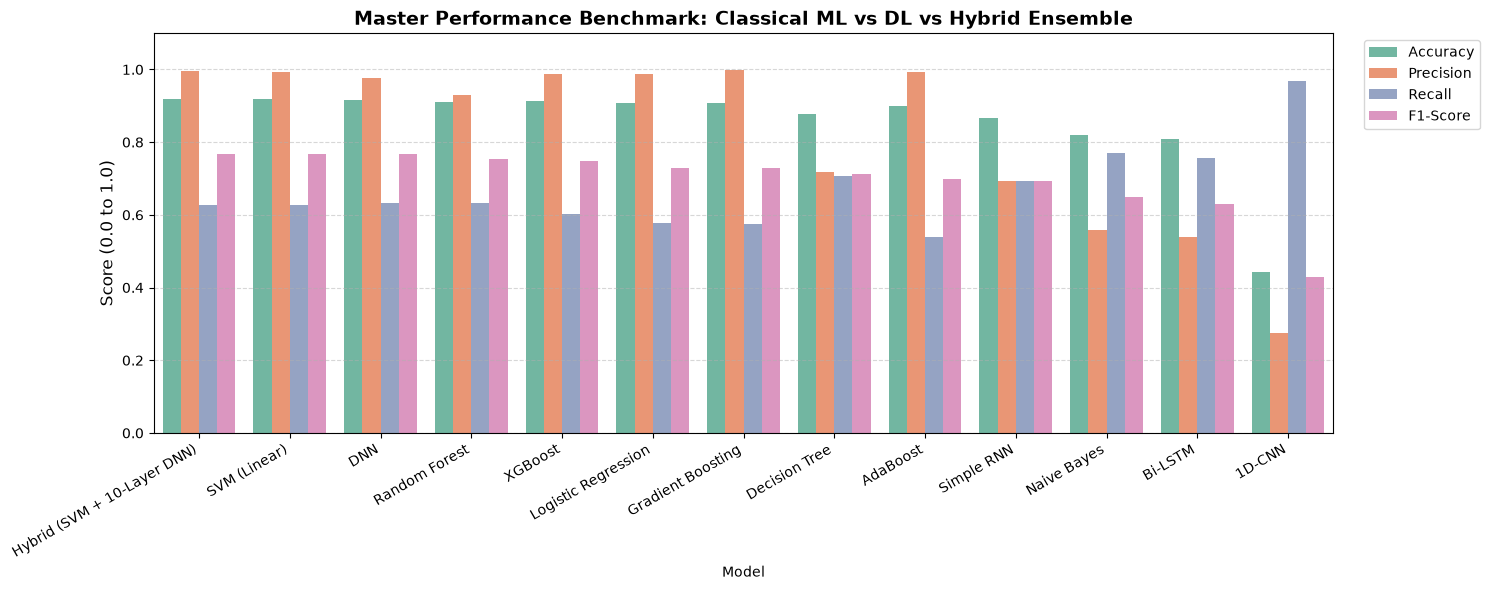

✅ Benchmark chart saved as 'saved_models/final_master_model_comparison.png'!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare clean results list
clean_results = [r for r in results if not r["Model"].startswith("Hybrid") and r["Model"] not in dl_results]

# Add all 4 DL models
for name, row in dl_comparison_df.iterrows():
    clean_results.append({"Model": name, **row.to_dict()})

# Add the final Hybrid model
clean_results.append(hybrid_metrics)

# 2. Build final Grand Comparison DataFrame
final_df = (
    pd.DataFrame(clean_results)[["Model", "Accuracy", "Precision", "Recall", "F1-Score"]]
    .drop_duplicates(subset=["Model"])
    .sort_values(by="F1-Score", ascending=False)
    .reset_index(drop=True)
)

print("\n--- 🏆 ALL MODELS BENCHMARK (CLASSICAL ML vs DL vs HYBRID) ---")
display(final_df)

# 3. Final Benchmark Bar Chart
plt.figure(figsize=(15, 6))
df_melted = final_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Master Performance Benchmark: Classical ML vs DL vs Hybrid Ensemble", fontsize=14, fontweight="bold")
plt.ylabel("Score (0.0 to 1.0)", fontsize=12)
plt.ylim(0.0, 1.1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

# Save comparison chart
plt.savefig("saved_models/final_master_model_comparison.png", dpi=300)
plt.show()
print("✅ Benchmark chart saved as 'saved_models/final_master_model_comparison.png'!")

### Final Model Hybrid Ensemble: SVM + DNN